In [ ]:
from datasets import load_dataset

ds = load_dataset(
    "stanfordnlp/imdb",
    data_files={"train": "plain_text/train-*"},
    split="train",
    verification_mode="no_checks",
)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [ ]:
ds

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

### Step 1: Preprocessing & Exploratory Data Analysis (EDA)
We will now clean the dataset, analyze length distributions, identify potential label leakage (explicit ratings), and create our stratified splits.

We use only the official training reviews during development. Labels are binary (0 = negative, 1 = positive); there is no neutral class. The unsupervised split is not used.

In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

# Keep the original row number to identify reviews later
train_df = pd.DataFrame(ds)
train_df['example_id'] = [f'train_{i:05d}' for i in range(len(train_df))]

print(f"Original train size: {len(train_df)}")

Original train size: 25000


In [ ]:
train_df.head()

,text,label,example_id
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001
2,If only to avoid making this type of film in t...,0,train_00002
3,This film was probably inspired by Godard's Ma...,0,train_00003
4,"Oh, brother...after hearing about this ridicul...",0,train_00004


In [ ]:
def clean_html(text):
    # Strip HTML tags like <br />
    return re.sub(r'<[^>]*>', ' ', text)

# 1. HTML Cleaning
train_df['cleaned_text'] = train_df['text'].apply(clean_html)

In [ ]:
train_df.head()

,text,label,example_id,cleaned_text
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001,"""I Am Curious: Yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,0,train_00002,If only to avoid making this type of film in t...
3,This film was probably inspired by Godard's Ma...,0,train_00003,This film was probably inspired by Godard's Ma...
4,"Oh, brother...after hearing about this ridicul...",0,train_00004,"Oh, brother...after hearing about this ridicul..."


In [ ]:
# 2. Normalize and Deduplicate
# Match exact duplicates after lowercasing and collapsing whitespace
# This does not detect paraphrases or other semantic near-duplicates
train_df['norm_text_for_dedup'] = (
    train_df['cleaned_text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
)

before_dedup = len(train_df)
train_df = train_df.drop_duplicates(subset=['norm_text_for_dedup']).copy()
after_dedup = len(train_df)

print(f"Removed {before_dedup - after_dedup} duplicate reviews from the training set.")
print(f"New training set size: {after_dedup}")

Removed 98 duplicate reviews from the training set.
New training set size: 24902


In [ ]:
# 3. Find Explicit Ratings
rating_pattern = r'\b\d{1,2}(?:\.\d+)?\s*(?:/|out\s+of)\s*10\b'

def find_explicit_ratings(text):
    return re.search(rating_pattern, text, re.IGNORECASE) is not None

train_df['has_explicit_rating'] = train_df['cleaned_text'].apply(find_explicit_ratings)
leakage_rate = train_df['has_explicit_rating'].mean() * 100

print(f"Reviews containing explicit ratings: {leakage_rate:.2f}%")
train_df.loc[train_df['has_explicit_rating'], ['text', 'label']].head(3)

Reviews containing explicit ratings: 8.70%


,text,label
3,This film was probably inspired by Godard's Ma...,0
19,Pros: Nothing<br /><br />Cons: Everything<br /...,0
21,1st watched 8/3/2003 - 2 out of 10(Dir-Brad Sy...,0


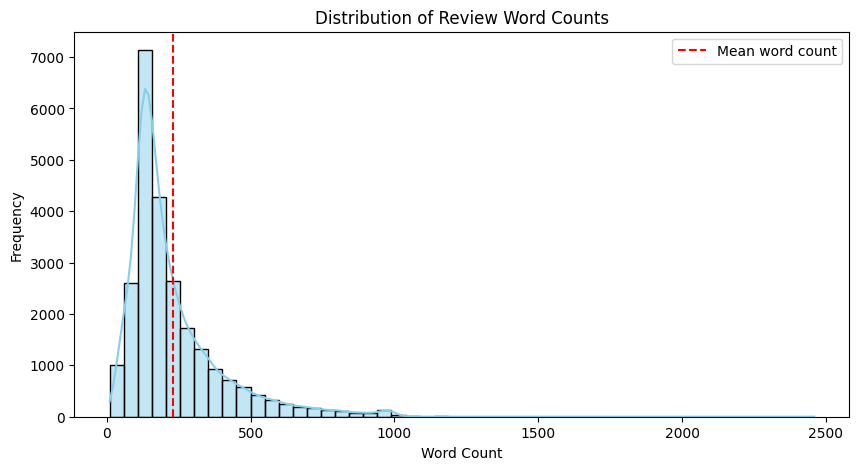

In [ ]:
# 4. Length Analysis (Word Count distribution)
train_df['word_count'] = train_df['cleaned_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
sns.histplot(train_df['word_count'], bins=50, kde=True, color='skyblue')
plt.axvline(train_df['word_count'].mean(), color='red', linestyle='--', label='Mean word count')
plt.title('Distribution of Review Word Counts')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [ ]:
print(f"Mean word count: {train_df['word_count'].mean():.1f}")
print(f"Median word count: {train_df['word_count'].median():.1f}")
print(f"Percentage of reviews exceeding 512 words: {(train_df['word_count'] > 512).mean() * 100:.2f}%")
print("Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.")

Mean word count: 231.7
Median word count: 173.0
Percentage of reviews exceeding 512 words: 7.45%
Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.


We will keep 5,000 reviews for development, with the same class balance as the training set. Using seed 42 gives us the same split each time.

In [ ]:
# 5. Create a Stratified Train/Dev Split
from sklearn.model_selection import train_test_split

dev_df, train_split_df = train_test_split(
    train_df,
    train_size=5000,
    stratify=train_df['label'],
    random_state=SEED
)
train_split_df = train_split_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)

In [ ]:
print(f"Train reviews: {len(train_split_df)}")
print(f"Dev reviews: {len(dev_df)}")
dev_df['label'].value_counts()

Train reviews: 19902
Dev reviews: 5000


,count
label,
1,2504
0,2496


### Step 2: TF-IDF Features
We will now turn the reviews into numerical features. We use single words and pairs of words, keeping stopwords so phrases like "not good" are retained. The vocabulary is learned from training reviews only.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

In [ ]:
X_train = vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev = vectorizer.transform(dev_df['cleaned_text'])

y_train = train_split_df['label']
y_dev = dev_df['label']

print(f"Training feature matrix: {X_train.shape}")
print(f"Dev feature matrix: {X_dev.shape}")

Training feature matrix: (19902, 364489)
Dev feature matrix: (5000, 364489)


### Step 3: Baseline Models
Let's start with Logistic Regression and try three values of C. We choose the one with the highest dev accuracy and also report macro-F1.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score

predictions = {}
scores = []

In [ ]:
def evaluate_model(model, X, name):
    pred = model.predict(X)
    predictions[name] = dev_df[['example_id', 'label']].assign(
        model=name, pred=pred, prob=model.predict_proba(X)[:, 1]
    )
    scores.append({
        'model': name,
        'accuracy': accuracy_score(y_dev, pred),
        'macro_f1': f1_score(y_dev, pred, average='macro')
    })

In [ ]:
# 1. Compare Three Values of C
lr_models = {}
for C in [0.1, 1, 10]:
    name = f'lr_C_{C:g}'
    model = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    model.fit(X_train, y_train)
    lr_models[name] = model
    evaluate_model(model, X_dev, name)

In [ ]:
# A tie keeps the smaller C, since we tried values in ascending order
lr_results = pd.DataFrame(scores).sort_values('accuracy', ascending=False, kind='stable')
best_lr_name = lr_results.iloc[0]['model']
best_lr = lr_models[best_lr_name]
best_C = best_lr.C

print(f"Selected C: {best_C}")
lr_results

Selected C: 10


,model,accuracy,macro_f1
2,lr_C_10,0.9012,0.901198
1,lr_C_1,0.8890,0.888980
0,lr_C_0.1,0.8592,0.859113


### Step 4: Preprocessing Ablation
We will now change one thing at a time, keeping the same split and selected C. First, does removing ratings such as "8/10" affect the result?

In [ ]:
# 1. Remove Explicit Ratings from Both Sets
def remove_explicit_ratings(text):
    return re.sub(rating_pattern, ' ', text, flags=re.IGNORECASE)

train_no_ratings = train_split_df['cleaned_text'].apply(remove_explicit_ratings)
dev_no_ratings = dev_df['cleaned_text'].apply(remove_explicit_ratings)

In [ ]:
# Fit a fresh vocabulary after removing the ratings
rating_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_ratings = rating_vectorizer.fit_transform(train_no_ratings)
X_dev_ratings = rating_vectorizer.transform(dev_no_ratings)

In [ ]:
rating_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
rating_model.fit(X_train_ratings, y_train)

evaluate_model(rating_model, X_dev_ratings, 'lr_no_ratings')
pd.DataFrame(scores).tail(1)

,model,accuracy,macro_f1
4,lr_no_ratings,0.9012,0.9012


Next, let's remove English stopwords. This also removes words like "not", which could change the meaning of a review.

In [ ]:
# 2. Try Stopword Removal on the Original Cleaned Text
stopword_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words='english'
)
X_train_stopwords = stopword_vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev_stopwords = stopword_vectorizer.transform(dev_df['cleaned_text'])

In [ ]:
stopword_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
stopword_model.fit(X_train_stopwords, y_train)

evaluate_model(stopword_model, X_dev_stopwords, 'lr_stopwords')

In [ ]:
# Compare all runs
results_df = pd.DataFrame(scores)
results_df

,model,accuracy,macro_f1
0,lr_C_0.1,0.8592,0.859113
1,lr_C_1,0.8890,0.888980
2,lr_C_10,0.9012,0.901198
3,naive_bayes,0.8828,0.882774
4,lr_no_ratings,0.9012,0.901200
5,lr_stopwords,0.8936,0.893589


In the first run, C = 10 gave 90.12% dev accuracy. Removing numeric ratings gave the same accuracy, while removing stopwords reduced it to 89.36%. We will keep stopwords for now. The rating check only covers the expressions matched by our regex.

### Step 5: A Closer Look at the Predictions
Overall accuracy does not show which class is harder. Let's compare precision, recall and the confusion matrices for our two baselines.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

lr_predictions = predictions[best_lr_name]
nb_predictions = predictions['naive_bayes']

print("Logistic Regression")
print(classification_report(y_dev, lr_predictions['pred'], target_names=['negative', 'positive']))

Logistic Regression
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      2496
    positive       0.90      0.90      0.90      2504

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



In [ ]:
print("Naive Bayes")
print(classification_report(y_dev, nb_predictions['pred'], target_names=['negative', 'positive']))

Naive Bayes
              precision    recall  f1-score   support

    negative       0.87      0.90      0.88      2496
    positive       0.90      0.87      0.88      2504

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



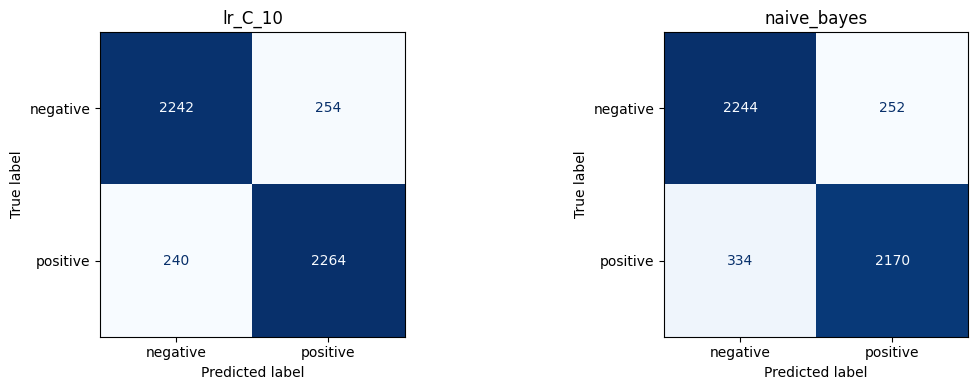

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, [best_lr_name, 'naive_bayes']):
    ConfusionMatrixDisplay.from_predictions(
        y_dev, predictions[name]['pred'], ax=ax,
        display_labels=['negative', 'positive'], cmap='Blues', colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

Are more confident predictions more often correct? Here, `prob` is the probability of a positive review, so confidence in the predicted class is the larger of `prob` and `1 - prob`.

In [ ]:
confidence = pd.concat([lr_predictions, nb_predictions], ignore_index=True)
confidence['correct'] = confidence['pred'] == confidence['label']
confidence['confidence'] = np.maximum(confidence['prob'], 1 - confidence['prob'])
confidence['bucket'] = pd.cut(
    confidence['confidence'], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True
)

In [ ]:
confidence_table = confidence.groupby(['model', 'bucket'], observed=False).agg(
    count=('correct', 'size'),
    accuracy=('correct', 'mean'),
    mean_confidence=('confidence', 'mean')
).reset_index()
confidence_table

,model,bucket,count,accuracy,mean_confidence
0,lr_C_10,"(0.499, 0.6]",397,0.564232,0.550505
1,lr_C_10,"(0.6, 0.7]",427,0.690867,0.651039
2,lr_C_10,"(0.7, 0.8]",552,0.817029,0.753329
3,lr_C_10,"(0.8, 0.9]",899,0.936596,0.854577
4,lr_C_10,"(0.9, 1.0]",2725,0.988624,0.964329
5,naive_bayes,"(0.499, 0.6]",789,0.623574,0.551871
6,naive_bayes,"(0.6, 0.7]",915,0.802186,0.654205
7,naive_bayes,"(0.7, 0.8]",1125,0.931556,0.752344
8,naive_bayes,"(0.8, 0.9]",1295,0.976834,0.850612
9,naive_bayes,"(0.9, 1.0]",876,0.998858,0.939849


### Step 6: DistilBERT
We will now fine-tune DistilBERT on the same training reviews. We keep the HTML cleaning and let its own tokenizer handle the text. Unlike TF-IDF, this model has a limited input length.

In [ ]:
import torch
from time import perf_counter
from datasets import Dataset
from scipy.special import softmax
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding, set_seed

model_name = 'distilbert/distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (training will be slow)')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tesla T4


First, how long are the reviews in word-pieces? We tokenize once without truncation so we can try different lengths later. The model also needs two special tokens, [CLS] and [SEP].

In [ ]:
for frame in [train_split_df, dev_df]:
    frame['tokens'] = tokenizer(
        frame['cleaned_text'].tolist(), add_special_tokens=False, truncation=False, verbose=False
    )['input_ids']
    frame['token_count'] = frame['tokens'].apply(len) + 2

train_split_df['token_count'].describe()

,token_count
count,19902.000000
mean,298.236459
std,222.179926
min,13.000000
25%,161.000000
50%,222.000000
75%,362.000000
max,3047.000000


At 128 tokens, 87.9% of training reviews are truncated.
At 256 tokens, 41.1% of training reviews are truncated.
At 512 tokens, 13.5% of training reviews are truncated.


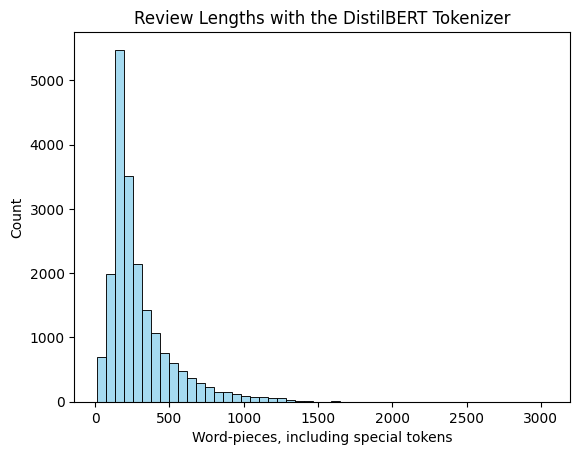

In [ ]:
for length in [128, 256, 512]:
    truncated = (train_split_df['token_count'] > length).mean() * 100
    print(f"At {length} tokens, {truncated:.1f}% of training reviews are truncated.")

sns.histplot(train_split_df['token_count'], bins=50, color='skyblue')
plt.xlabel('Word-pieces, including special tokens')
plt.title('Review Lengths with the DistilBERT Tokenizer')
plt.show()

We will normally keep the start of a review. For the head+tail experiment, we keep equal amounts from the beginning and end. At a 256-token budget, this means 127 + 127 word-pieces plus the two special tokens. Short reviews are kept whole.

In [ ]:
def trim_review(tokens, max_length, head_tail=False):
    budget = max_length - 2
    if head_tail and len(tokens) > budget:
        half = budget // 2
        tokens = tokens[:half] + tokens[-(budget - half):]
    else:
        tokens = tokens[:budget]
    return [tokenizer.cls_token_id] + tokens + [tokenizer.sep_token_id]

In [ ]:
def make_dataset(frame, max_length, head_tail=False):
    input_ids = [trim_review(ids, max_length, head_tail) for ids in frame['tokens']]
    return Dataset.from_dict({'input_ids': input_ids, 'labels': frame['label'].tolist()})

# Pad only to the longest review in each batch
collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenizer.decode(trim_review(train_split_df.iloc[0]['tokens'], 128)))

[CLS] in conception a splendid film, investigating the tensions that occur in family life in the idyllic setting of galiano island off the coast of british columbia, _ the lotus eaters _ is marred by the fact that it has been packaged as a made - for - tv movie, diminishing itself throughout by the addition of chirpy music over potentially powerful scenes, as if to get ready for the interruption of commercials. a pity, really. [SEP]


To fit a 4 GB GPU, we use batches of 4 and accumulate gradients over four batches, giving an effective batch size of 16. Mixed precision and gradient checkpointing reduce memory use. We use AdamW with weight decay 0.01 and a linear learning-rate schedule, keeping these settings fixed across runs.

In [ ]:
training_args = TrainingArguments(
    output_dir='.', num_train_epochs=2, learning_rate=2e-5,
    per_device_train_batch_size=4, gradient_accumulation_steps=4,
    per_device_eval_batch_size=8, optim='adamw_torch', weight_decay=0.01,
    lr_scheduler_type='linear', warmup_steps=0,
    fp16=torch.cuda.is_available(), gradient_checkpointing=True,
    seed=SEED, data_seed=SEED, dataloader_num_workers=0,
    save_strategy='no', logging_strategy='no', report_to='none', disable_tqdm=True
)

This helper starts from the original pretrained weights each time. We train for two epochs, then predict on dev. Training time excludes downloading, tokenization and dev prediction.

In [ ]:
def classification_loss(outputs, labels, num_items_in_batch=None):
    # Average over all reviews in the accumulated batch, including a partial batch
    loss = torch.nn.functional.cross_entropy(outputs.logits.float(), labels, reduction='sum')
    count = num_items_in_batch if num_items_in_batch is not None else labels.numel()
    return loss / count

In [ ]:
def fit_distilbert(frame, max_length=256, head_tail=False):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    trainer = Trainer(model=model, args=training_args, data_collator=collator,
                      train_dataset=make_dataset(frame, max_length, head_tail),
                      compute_loss_func=classification_loss)
    start = perf_counter()
    trainer.train()
    seconds = perf_counter() - start
    output = trainer.predict(make_dataset(dev_df, max_length, head_tail))
    prob = softmax(output.predictions, axis=1)[:, 1]
    model = model.cpu()
    del trainer
    torch.cuda.empty_cache()
    return model, prob, seconds

In [ ]:
model_256, prob_256, seconds_256 = fit_distilbert(train_split_df)
print(f"Dev accuracy: {accuracy_score(y_dev, prob_256 >= 0.5):.4f}")
print(f"Training time: {seconds_256 / 60:.1f} minutes")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '481', 'train_samples_per_second': '82.75', 'train_steps_per_second': '5.173', 'train_loss': '0.2353', 'epoch': '2'}
Dev accuracy: 0.9088
Training time: 8.0 minutes


### Step 7: How Much of a Review Does the Model Need?
Experiment A compares 128, 256 and 512 tokens, plus head+tail at 256. We reuse the 256-token run above. All runs use the same reviews, seed and training settings.

In [ ]:
model_128, prob_128, seconds_128 = fit_distilbert(train_split_df, max_length=128)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '473.6', 'train_samples_per_second': '84.04', 'train_steps_per_second': '5.253', 'train_loss': '0.2875', 'epoch': '2'}


In [ ]:
model_512, prob_512, seconds_512 = fit_distilbert(train_split_df, max_length=512)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '670', 'train_samples_per_second': '59.41', 'train_steps_per_second': '3.714', 'train_loss': '0.2098', 'epoch': '2'}


In [ ]:
model_head_tail, prob_head_tail, seconds_head_tail = fit_distilbert(
    train_split_df, max_length=256, head_tail=True
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '481.4', 'train_samples_per_second': '82.68', 'train_steps_per_second': '5.168', 'train_loss': '0.2161', 'epoch': '2'}


In [ ]:
bert_probs = [prob_128, prob_256, prob_512, prob_head_tail]
length_results = pd.DataFrame({
    'setting': ['Head 128', 'Head 256', 'Head 512', 'Head+tail 256'],
    'max_length': [128, 256, 512, 256], 'head_tail': [False, False, False, True],
    'accuracy': [accuracy_score(y_dev, p >= 0.5) for p in bert_probs],
    'macro_f1': [f1_score(y_dev, p >= 0.5, average='macro') for p in bert_probs],
    'minutes': np.array([seconds_128, seconds_256, seconds_512, seconds_head_tail]) / 60
})
length_results

,setting,max_length,head_tail,accuracy,macro_f1,minutes
0,Head 128,128,False,0.8806,0.880572,7.900574
1,Head 256,256,False,0.9088,0.908799,8.023774
2,Head 512,512,False,0.9262,0.926200,11.173291
3,Head+tail 256,256,True,0.9236,0.923600,8.030882


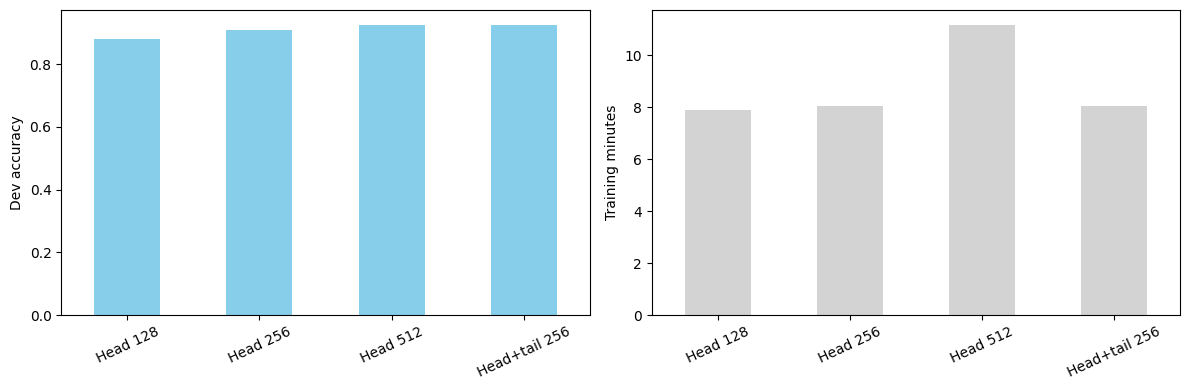

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
length_results.plot.bar(x='setting', y='accuracy', ax=axes[0], legend=False, color='skyblue')
length_results.plot.bar(x='setting', y='minutes', ax=axes[1], legend=False, color='lightgray')
axes[0].set_ylabel('Dev accuracy')
axes[1].set_ylabel('Training minutes')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

We choose the best dev accuracy for the final comparison.

In [ ]:
best_row = length_results.sort_values(
    ['accuracy', 'max_length', 'head_tail'], ascending=[False, True, True]
).iloc[0]
best_index = int(best_row.name)
best_bert = [model_128, model_256, model_512, model_head_tail][best_index]
best_bert_prob = bert_probs[best_index]
best_length = int(best_row['max_length'])
best_head_tail = bool(best_row['head_tail'])
print(f"Selected setting: {best_row['setting']}")

Selected setting: Head 512


### Step 8: How Much Labelled Data Do We Need?
Experiment B compares 1,000, 5,000 and all 19,902 training reviews. We create stratified subsets and give exactly the same reviews to both models.

C stays fixed at the value selected earlier. DistilBERT stays at 256 tokens and two epochs, so input length does not change along the learning curve. Each smaller neural model starts from the pretrained base model.

In [ ]:
train_5000, _ = train_test_split(
    train_split_df, train_size=5000, stratify=train_split_df['label'], random_state=SEED
)
train_1000, _ = train_test_split(
    train_5000, train_size=1000, stratify=train_5000['label'], random_state=SEED
)
print(train_1000['label'].value_counts())
print(train_5000['label'].value_counts())

label
1    501
0    499
Name: count, dtype: int64
label
1    2504
0    2496
Name: count, dtype: int64


In [ ]:
def fit_small_baseline(frame):
    start = perf_counter()
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    features = tfidf.fit_transform(frame['cleaned_text'])
    model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
    model.fit(features, frame['label'])
    seconds = perf_counter() - start
    prob = model.predict_proba(tfidf.transform(dev_df['cleaned_text']))[:, 1]
    return prob, seconds

In [ ]:
lr_prob_1000, lr_seconds_1000 = fit_small_baseline(train_1000)
lr_prob_5000, lr_seconds_5000 = fit_small_baseline(train_5000)
lr_prob_full, lr_seconds_full = fit_small_baseline(train_split_df)

In [ ]:
model_1000, prob_1000, seconds_1000 = fit_distilbert(train_1000)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '24.26', 'train_samples_per_second': '82.44', 'train_steps_per_second': '5.194', 'train_loss': '0.4808', 'epoch': '2'}


In [ ]:
model_5000, prob_5000, seconds_5000 = fit_distilbert(train_5000)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'train_runtime': '121.8', 'train_samples_per_second': '82.12', 'train_steps_per_second': '5.141', 'train_loss': '0.2877', 'epoch': '2'}


In [ ]:
sizes = [1000, 5000, len(train_split_df)]
learning_curve = pd.DataFrame({
    'train_size': sizes * 2,
    'model': ['Logistic Regression'] * 3 + ['DistilBERT'] * 3,
    'accuracy': [accuracy_score(y_dev, p >= 0.5) for p in
                 [lr_prob_1000, lr_prob_5000, lr_prob_full, prob_1000, prob_5000, prob_256]],
    'minutes': np.array([lr_seconds_1000, lr_seconds_5000, lr_seconds_full,
                         seconds_1000, seconds_5000, seconds_256]) / 60
})
learning_curve

,train_size,model,accuracy,minutes
0,1000,Logistic Regression,0.8392,0.008981
1,5000,Logistic Regression,0.8728,0.057472
2,19902,Logistic Regression,0.9012,0.195719
3,1000,DistilBERT,0.8648,0.411288
4,5000,DistilBERT,0.8902,2.036185
5,19902,DistilBERT,0.9088,8.023774


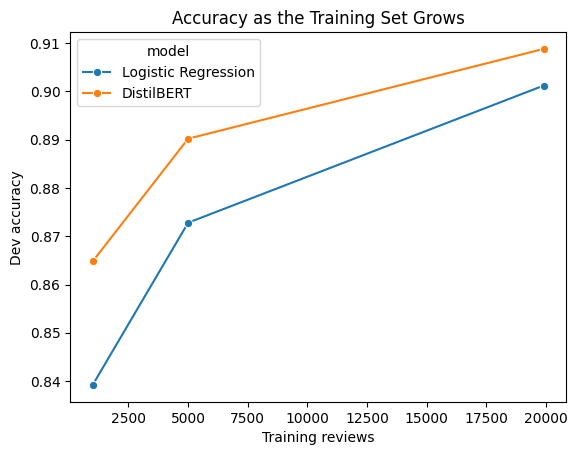

In [ ]:
sns.lineplot(data=learning_curve, x='train_size', y='accuracy', hue='model', marker='o')
plt.xlabel('Training reviews')
plt.ylabel('Dev accuracy')
plt.title('Accuracy as the Training Set Grows')
plt.show()

The three points show where a model leads at the sizes we tested; they do not locate an exact crossover. The training times also use different hardware: Logistic Regression runs on the CPU and DistilBERT on the GPU, when available. TF-IDF fitting is included in the baseline times.

### Step 9: Where Do the models Fail?
We will now compare the selected DistilBERT model with Logistic Regression on dev. All predictions follow the same review order, so we can inspect cases where the models disagree.

In [ ]:
bert_predictions = dev_df[['example_id', 'label']].assign(
    model='DistilBERT', pred=(best_bert_prob >= 0.5).astype(int), prob=best_bert_prob
)
print(classification_report(y_dev, bert_predictions['pred'], target_names=['negative', 'positive']))

              precision    recall  f1-score   support

    negative       0.92      0.93      0.93      2496
    positive       0.93      0.92      0.93      2504

    accuracy                           0.93      5000
   macro avg       0.93      0.93      0.93      5000
weighted avg       0.93      0.93      0.93      5000



In [ ]:
comparison = dev_df[['example_id', 'label', 'cleaned_text', 'token_count']].copy()
comparison['lr_pred'] = lr_predictions['pred'].to_numpy()
comparison['bert_pred'] = bert_predictions['pred'].to_numpy()
comparison['lr_correct'] = comparison['lr_pred'] == comparison['label']
comparison['bert_correct'] = comparison['bert_pred'] == comparison['label']
comparison['truncated'] = comparison['token_count'] > best_length
comparison.groupby('truncated').agg(
    reviews=('label', 'size'), lr_accuracy=('lr_correct', 'mean'), bert_accuracy=('bert_correct', 'mean')
)

,reviews,lr_accuracy,bert_accuracy
truncated,,,
False,4366,0.899450,0.929684
True,634,0.913249,0.902208


In [ ]:
disagreements = comparison.loc[comparison['lr_pred'] != comparison['bert_pred']]
print(f"The models disagree on {len(disagreements)} dev reviews.")
disagreements[['label', 'lr_pred', 'bert_pred', 'cleaned_text']].head()

The models disagree on 491 dev reviews.


,label,lr_pred,bert_pred,cleaned_text
15,0,0,1,The producers made a big mistake casting Mark ...
20,1,0,1,Normally I don't like series at all. They're a...
27,0,0,1,"A battleship is sinking... Its survivors, hang..."
53,0,1,0,I saw this movie a few days ago... what the he...
66,0,0,1,"ORCA is not exactly bad, but it's not really R..."


### Step 10: Confidence
We will repeat the confidence check with DistilBERT. Are the confident mistakes different from the uncertain ones? These are still dev diagnostics, since we used dev to select our models.

In [ ]:
confidence = pd.concat([lr_predictions, bert_predictions], ignore_index=True)
confidence['correct'] = confidence['pred'] == confidence['label']
confidence['confidence'] = np.maximum(confidence['prob'], 1 - confidence['prob'])
confidence['bucket'] = pd.cut(
    confidence['confidence'], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True
)
confidence.groupby(['model', 'bucket'], observed=False).agg(
    reviews=('correct', 'size'), accuracy=('correct', 'mean'), mean_confidence=('confidence', 'mean')
)

reviews  accuracy  mean_confidence
model      bucket                                          
DistilBERT (0.499, 0.6]       42  0.571429         0.554453
           (0.6, 0.7]         61  0.540984         0.648352
           (0.7, 0.8]         87  0.586207         0.759887
           (0.8, 0.9]        144  0.625000         0.856190
           (0.9, 1.0]       4666  0.950064         0.992364
lr_C_10    (0.499, 0.6]      397  0.564232         0.550505
           (0.6, 0.7]        427  0.690867         0.651039
           (0.7, 0.8]        552  0.817029         0.753329
           (0.8, 0.9]        899  0.936596         0.854577
           (0.9, 1.0]       2725  0.988624         0.964329

### Step 11: Final Test Evaluation
**Freeze point:** We now fix the selected C, preprocessing and DistilBERT truncation setting. We use the trained models as they are and evaluate the official test set.

In [ ]:
print(f"Logistic Regression: C={best_C}, stopwords and ratings kept")
print(f"DistilBERT: {best_row['setting']}, two epochs on {len(train_split_df)} reviews")

test_ds = load_dataset('stanfordnlp/imdb', data_files={'test': 'plain_text/test-*'}, split='test', verification_mode='no_checks',)
test_df = pd.DataFrame(test_ds)
test_df['cleaned_text'] = test_df['text'].apply(clean_html)
test_df['tokens'] = tokenizer(
    test_df['cleaned_text'].tolist(), add_special_tokens=False, truncation=False, verbose=False
)['input_ids']
y_test = test_df['label'].to_numpy()

Logistic Regression: C=10, stopwords and ratings kept
DistilBERT: Head 512, two epochs on 19902 reviews


plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [ ]:
lr_test_prob = best_lr.predict_proba(vectorizer.transform(test_df['cleaned_text']))[:, 1]
lr_test_pred = (lr_test_prob >= 0.5).astype(int)

In [ ]:
test_trainer = Trainer(model=best_bert, args=training_args, data_collator=collator)
test_output = test_trainer.predict(make_dataset(test_df, best_length, best_head_tail))
bert_test_prob = softmax(test_output.predictions, axis=1)[:, 1]
bert_test_pred = (bert_test_prob >= 0.5).astype(int)
best_bert.cpu()
del test_trainer
torch.cuda.empty_cache()

In [ ]:
test_predictions = {'Logistic Regression': lr_test_pred, 'DistilBERT': bert_test_pred}
test_results = pd.DataFrame([
    {'model': name, 'accuracy': accuracy_score(y_test, pred),
     'macro_f1': f1_score(y_test, pred, average='macro')}
    for name, pred in test_predictions.items()
])
test_results

,model,accuracy,macro_f1
0,Logistic Regression,0.90320,0.90320
1,DistilBERT,0.92892,0.92892


In [ ]:
for name, pred in test_predictions.items():
    print(name)
    print(classification_report(y_test, pred, target_names=['negative', 'positive'], digits=4))

Logistic Regression
              precision    recall  f1-score   support

    negative     0.9038    0.9024    0.9031     12500
    positive     0.9026    0.9040    0.9033     12500

    accuracy                         0.9032     25000
   macro avg     0.9032    0.9032    0.9032     25000
weighted avg     0.9032    0.9032    0.9032     25000

DistilBERT
              precision    recall  f1-score   support

    negative     0.9291    0.9287    0.9289     12500
    positive     0.9287    0.9291    0.9289     12500

    accuracy                         0.9289     25000
   macro avg     0.9289    0.9289    0.9289     25000
weighted avg     0.9289    0.9289    0.9289     25000



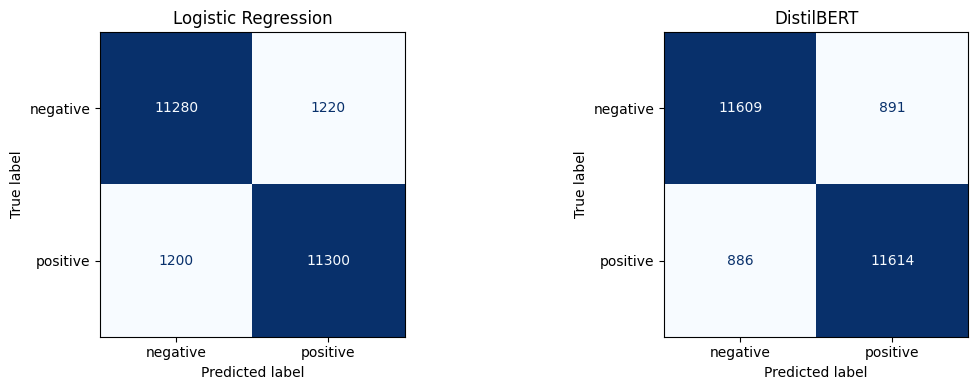

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, display_labels=['negative', 'positive'], cmap='Blues', colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()